In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")

# input dari Data Preparation, kali ini label kelas tidak dipakai untuk melatih (unsupervised)
data = pd.read_csv("../data/kbbi_bersih.csv")
data["contoh"] = data["contoh"].fillna("")
data["suku_kata"] = data["nama"].str.count(r"\.") + 1
data["huruf"] = data["nama"].str.replace(".", "", regex=False).str.len()
data["panjang_makna"] = data["submakna"].str.len()
data["jumlah_kata_makna"] = data["submakna"].str.split().str.len()
data["ada_contoh"] = (data["contoh"] != "").astype(int)

# outlier panjang makna dipotong seperti di Data Preparation
data["panjang_makna"] = data["panjang_makna"].clip(upper=data["panjang_makna"].quantile(0.99))

num_cols = ["suku_kata", "huruf", "panjang_makna", "jumlah_kata_makna", "ada_contoh"]
X_asli = data[num_cols].to_numpy(dtype=float)
X = MinMaxScaler().fit_transform(X_asli)                     # K-Means wajib diskalakan

# dua fitur dulu supaya prosesnya bisa digambar
X2 = X[:, [2, 1]]
print(X.shape, X2.shape)

(99281, 5) (99281, 2)


In [2]:
# K-Means manual: inisialisasi, assign, update, ulangi sampai centroid stabil
def kmeans_manual(X, K, seed=42, maks_iterasi=100):
    rng = np.random.default_rng(seed)
    centroid = X[rng.choice(len(X), K, replace=False)]        # inisialisasi acak
    riwayat = [centroid.copy()]
    for i in range(maks_iterasi):
        jarak = np.linalg.norm(X[:, None, :] - centroid[None, :, :], axis=2)
        label = jarak.argmin(axis=1)                          # assign: data ke centroid terdekat
        baru = np.array([X[label == k].mean(axis=0) if (label == k).any() else centroid[k] for k in range(K)])  # update: rata-rata
        geser = np.abs(baru - centroid).max()
        centroid = baru
        riwayat.append(centroid.copy())
        print(f"Iterasi {i + 1}: perpindahan centroid terbesar = {geser:.5f}")
        if geser < 1e-4:                                      # konvergen
            break
    return label, centroid, riwayat

label2, centroid2, riwayat = kmeans_manual(X2, K=3)
print("Ukuran cluster:", np.bincount(label2))

Iterasi 1: perpindahan centroid terbesar = 0.05153
Iterasi 2: perpindahan centroid terbesar = 0.03698
Iterasi 3: perpindahan centroid terbesar = 0.02331
Iterasi 4: perpindahan centroid terbesar = 0.01355
Iterasi 5: perpindahan centroid terbesar = 0.01292
Iterasi 6: perpindahan centroid terbesar = 0.00422
Iterasi 7: perpindahan centroid terbesar = 0.00303
Iterasi 8: perpindahan centroid terbesar = 0.00186
Iterasi 9: perpindahan centroid terbesar = 0.00182
Iterasi 10: perpindahan centroid terbesar = 0.00064
Iterasi 11: perpindahan centroid terbesar = 0.00000
Ukuran cluster: [19638 32037 47606]


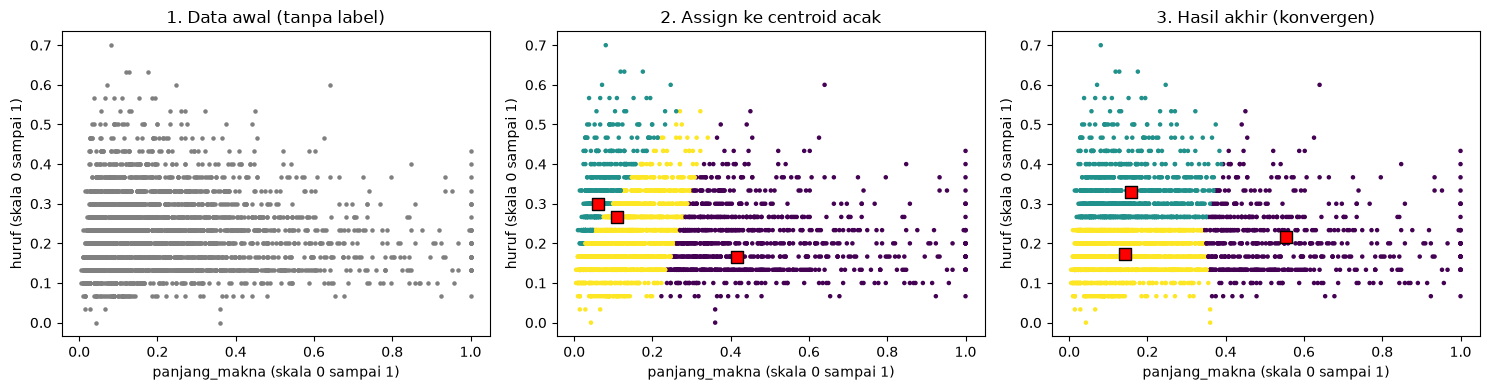

In [3]:
# visualisasi: data awal, iterasi pertama (assign), dan hasil akhir
idx = np.random.default_rng(0).choice(len(X2), 3000, replace=False)
awal = np.linalg.norm(X2[idx][:, None, :] - riwayat[0][None, :, :], axis=2).argmin(axis=1)
akhir = np.linalg.norm(X2[idx][:, None, :] - centroid2[None, :, :], axis=2).argmin(axis=1)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(*X2[idx].T, s=5, c="gray")
ax[0].set_title("1. Data awal (tanpa label)")
ax[1].scatter(*X2[idx].T, s=5, c=awal, cmap="viridis")
ax[1].scatter(*riwayat[0].T, c="red", marker="s", s=80, edgecolors="k")
ax[1].set_title("2. Assign ke centroid acak")
ax[2].scatter(*X2[idx].T, s=5, c=akhir, cmap="viridis")
ax[2].scatter(*centroid2.T, c="red", marker="s", s=80, edgecolors="k")
ax[2].set_title("3. Hasil akhir (konvergen)")
for a in ax:
    a.set_xlabel("panjang_makna (skala 0 sampai 1)")
    a.set_ylabel("huruf (skala 0 sampai 1)")
plt.tight_layout()
plt.show()

In [4]:
# perbandingan dengan KMeans scikit-learn memakai centroid awal yang sama
km = KMeans(n_clusters=3, init=riwayat[0], n_init=1).fit(X2)
print("Centroid manual:\n", centroid2.round(4))
print("Centroid sklearn:\n", km.cluster_centers_.round(4))
print("Hasil sama:", np.allclose(np.sort(centroid2, axis=0), np.sort(km.cluster_centers_, axis=0), atol=1e-3))

Centroid manual:
 [[0.5535 0.2166]
 [0.1567 0.3297]
 [0.143  0.173 ]]
Centroid sklearn:
 [[0.5535 0.2166]
 [0.1567 0.3297]
 [0.143  0.173 ]]
Hasil sama: True


In [5]:
# segmentasi pada data KBBI dengan lima fitur angka, K=3
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
data["cluster"] = km.labels_

profil = data.groupby("cluster")[num_cols].mean()
profil.insert(0, "jumlah_data", data["cluster"].value_counts().sort_index())
profil.round(2)

,jumlah_data,suku_kata,huruf,panjang_makna,jumlah_kata_makna,ada_contoh
cluster,,,,,,
0,16444,3.11,7.56,121.67,17.31,0.0
1,26528,3.20,8.30,42.39,5.45,1.0
2,56309,3.14,7.92,33.08,4.52,0.0


In [6]:
# K-Means berbeda dari KNN: label kelas tidak dipakai saat melatih, hanya untuk mengintip hasil clusternya
pd.crosstab(data["cluster"], data["kelas_utama"], normalize="index").round(3) * 100

kelas_utama,Adjektiva,Nomina,Verba
cluster,,,
0,4.0,90.0,6.0
1,16.3,34.1,49.6
2,10.0,65.7,24.3


In [7]:
# sensitif terhadap skala: pusat cluster tanpa scaling (satuan asli) dibandingkan dengan dengan scaling
km_mentah = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_asli)
mentah = pd.DataFrame(km_mentah.cluster_centers_, columns=num_cols).round(2)
mentah["jumlah_data"] = np.bincount(km_mentah.labels_)
print("Tanpa scaling:")
print(mentah.sort_values("panjang_makna"))

Tanpa scaling:
   suku_kata  huruf  panjang_makna  jumlah_kata_makna  ada_contoh  jumlah_data
0       3.15   8.05          24.31               3.25        0.30        60291
1       3.19   7.94          72.72               9.84        0.26        30456
2       3.05   7.46         152.94              21.99        0.10         8534


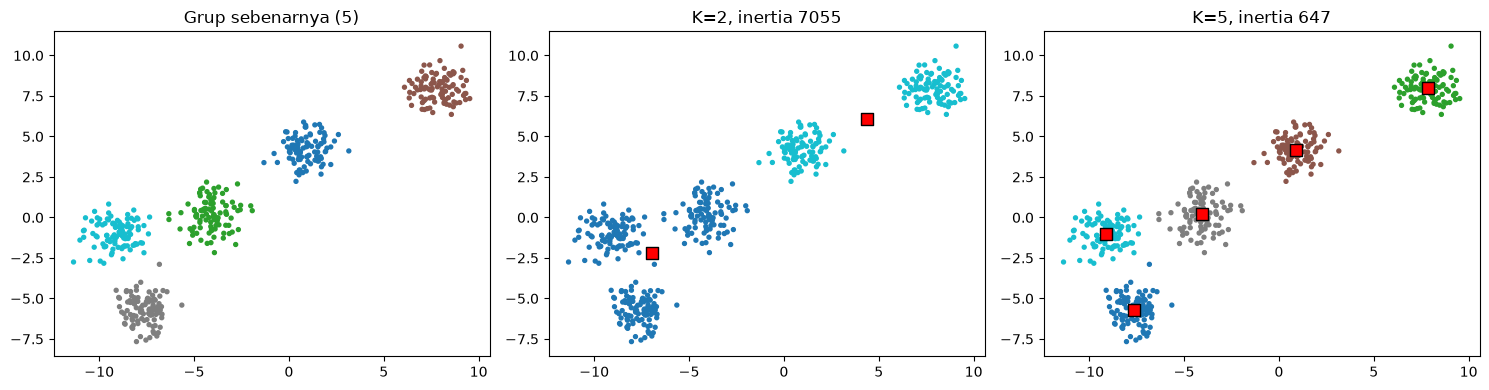

In [8]:
# tantangan memilih K: data sebenarnya punya 5 grup
Xb, yb = make_blobs(n_samples=500, centers=5, cluster_std=0.8, random_state=3)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(*Xb.T, s=8, c=yb, cmap="tab10")
ax[0].set_title("Grup sebenarnya (5)")
for a, k in zip(ax[1:], [2, 5]):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xb)
    a.scatter(*Xb.T, s=8, c=m.labels_, cmap="tab10")
    a.scatter(*m.cluster_centers_.T, c="red", marker="s", s=80, edgecolors="k")
    a.set_title(f"K={k}, inertia {m.inertia_:.0f}")
plt.tight_layout()
plt.show()

In [9]:
# sensitif inisialisasi acak: satu kali inisialisasi acak dengan seed berbeda
hasil = []
for seed in range(8):
    m = KMeans(n_clusters=5, init="random", n_init=1, random_state=seed).fit(Xb)
    hasil.append({"seed": seed, "inertia": m.inertia_})
tabel = pd.DataFrame(hasil)
print(tabel.round(1).T)

terbaik = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42).fit(Xb)
print(f"k-means++ dengan 10 kali percobaan: inertia {terbaik.inertia_:.1f}")

             0      1       2      3       4       5       6      7
seed       0.0    1.0     2.0    3.0     4.0     5.0     6.0    7.0
inertia  646.5  646.6  1919.5  646.5  1806.4  1800.4  1806.0  646.5
k-means++ dengan 10 kali percobaan: inertia 646.5


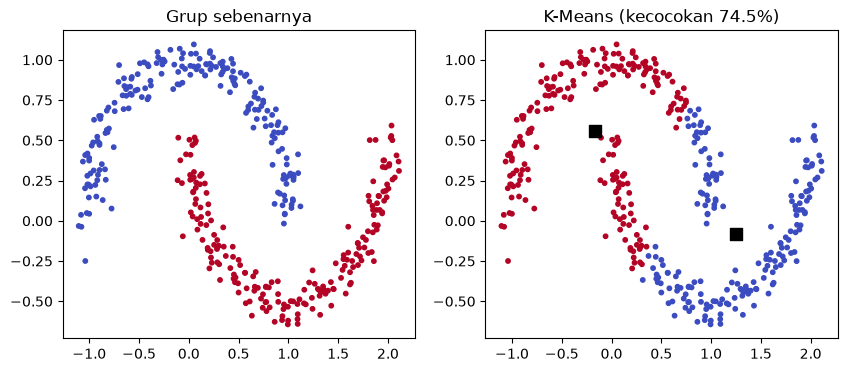

In [10]:
# hanya untuk cluster bulat: data bulan sabit gagal dikelompokkan
Xm, ym = make_moons(n_samples=400, noise=0.07, random_state=42)
mm = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xm)
cocok = max((mm.labels_ == ym).mean(), (mm.labels_ != ym).mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(*Xm.T, s=10, c=ym, cmap="coolwarm")
ax[0].set_title("Grup sebenarnya")
ax[1].scatter(*Xm.T, s=10, c=mm.labels_, cmap="coolwarm")
ax[1].scatter(*mm.cluster_centers_.T, c="k", marker="s", s=80)
ax[1].set_title(f"K-Means (kecocokan {cocok:.1%})")
plt.show()

### Analisis

K-Means manual berhenti (konvergen) setelah 11 iterasi, dan pusat cluster-nya sama persis dengan hasil KMeans scikit-learn yang dimulai dari centroid awal yang sama. Pada grafik terlihat centroid berpindah dari posisi acak ke pusat kerumunan data, dan data di perbatasan berpindah cluster di sepanjang proses.

Pada data KBBI dengan lima fitur dan K=3, terbentuk tiga segmen. Segmen pertama (16.444 data) berisi makna yang panjang (rata-rata 122 karakter) tanpa contoh kalimat, dan 90 persennya nomina. Segmen kedua (26.528 data) berisi semua entri yang punya contoh kalimat, dengan komposisi paling beragam (49,6 persen verba, 34,1 persen nomina, 16,3 persen adjektiva). Segmen ketiga (56.309 data) berisi makna pendek (rata-rata 33 karakter) tanpa contoh, dan 65,7 persennya nomina. Label kelas tidak dipakai saat melatih, jadi kemiripan dengan kelas ini muncul sendiri dari pola data, berbeda dengan KNN yang butuh label.

Pengaruh skala terlihat pada hasil tanpa scaling: ketiga cluster hanya dibedakan oleh panjang_makna (24, 73, dan 153 karakter) sedangkan fitur lain hampir sama, sehingga ada_contoh tidak ikut menentukan segmen. Pada data buatan, K yang salah memberi hasil buruk: K=2 untuk data dengan 5 grup menghasilkan inertia 7.055, jauh lebih besar dari 647 pada K=5. Inisialisasi acak juga berpengaruh. Dari 8 percobaan, 4 mendapat inertia terbaik (646,5) dan 4 terjebak di hasil jelek sekitar 1.800 sampai 1.920, sedangkan k-means++ dengan 10 kali percobaan langsung mendapat 646,5. Terakhir, pada data bulan sabit K-Means hanya cocok 74,5 persen dengan grup sebenarnya karena cluster-nya tidak bulat.

In [11]:
# refleksi: segmentasi pelanggan e-commerce (K=3)
pd.DataFrame({
    "Cluster": [1, 2, 3],
    "Nama": ["Sultan", "Pelanggan hemat rutin", "Pelanggan coba-coba"],
    "Ciri": ["Uang banyak, transaksi banyak", "Uang sedikit, transaksi banyak", "Uang sedikit, transaksi sedikit"],
    "Strategi": ["Promo premium", "Program loyalitas", "Diskon ongkir agar belanja lagi"],
})

,Cluster,Nama,Ciri,Strategi
0,1,Sultan,"Uang banyak, transaksi banyak",Promo premium
1,2,Pelanggan hemat rutin,"Uang sedikit, transaksi banyak",Program loyalitas
2,3,Pelanggan coba-coba,"Uang sedikit, transaksi sedikit",Diskon ongkir agar belanja lagi
